In [1]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'
import random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import keras
from keras import layers, ops
from scipy.ndimage import label, find_objects
print('keras', keras.__version__)

# ---- Path set karo ----
try:                                    
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/sadak_project')
except ImportError:                     # VS Code / laptop
    ROOT = Path('sadak_project')        # <-- apna path (jaise Path(r'C:/DL/sadak_project')

SIZE, CROP = 512, 256                   # sab photos 512x512 par laate hain
EPOCHS = 2                             # 
IMG_EXT = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')
(ROOT/'runs').mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT.resolve(), '| exists:', ROOT.exists())

keras 3.15.1
ROOT: C:\Users\VAIBHAV\Desktop\SadakNazar – Pothole Detection & Priority System\SadakNazar\SadakNazar\sadak_project | exists: True


## : Dataset dhundo aur check karo
## Folder ke naam (`val`/`valid`/`validation`) khud pehchan leta hai. Kuch khaali ho to yahin saaf error aayega.

In [2]:
def list_images(d):
    d = Path(d)
    return sorted(p for p in d.glob('*') if p.suffix.lower() in IMG_EXT) if d.exists() else []

def find_split(name, aliases):
    for base in (ROOT/'data', ROOT):
        for a in aliases:
            d = base/a
            if (d/'images').exists():
                return d
    return None

SPLIT = {
    'train': find_split('train', ['train', 'training']),
    'val':   find_split('val',   ['val', 'valid', 'validation']),
    'test':  find_split('test',  ['test', 'testing']),
}
print({k: (str(v) if v else None) for k, v in SPLIT.items()})

assert SPLIT['train'] is not None and len(list_images(SPLIT['train']/'images')) > 0, (
    "Train images nahi mili! Check karo: ROOT sahi hai? images ke andar .jpg/.png files hain? "
    "Folder structure: sadak_project/data/train/images aur .../labels")

# val ya test na ho to sabko mila kar 70/15/15 split banao (COPY, original safe)
if SPLIT['val'] is None or SPLIT['test'] is None:
    pool = []
    for k, d in SPLIT.items():
        if d is not None:
            pool += [(p, d/'labels'/(p.stem + '.txt')) for p in list_images(d/'images')]
    random.Random(42).shuffle(pool)
    n = len(pool); a, b = int(0.7*n), int(0.85*n)
    parts = {'train': pool[:a], 'val': pool[a:b], 'test': pool[b:]}
    for k, items in parts.items():
        for sub in ('images', 'labels'):
            (ROOT/'auto_split'/k/sub).mkdir(parents=True, exist_ok=True)
        for img, lbl in items:
            shutil.copy(img, ROOT/'auto_split'/k/'images'/img.name)
            if lbl.exists():
                shutil.copy(lbl, ROOT/'auto_split'/k/'labels'/lbl.name)
    SPLIT = {k: ROOT/'auto_split'/k for k in parts}
    print('val/test nahi mile, auto_split bana diya:', {k: len(v) for k, v in parts.items()})

{'train': 'sadak_project\\data\\train', 'val': 'sadak_project\\data\\val', 'test': 'sadak_project\\data\\test'}


## Data pipeline
## Photos 512x512 par aati hain, labels se mask banta hai, training me gaddhe ke aas-paas ke 256x256 crops lete hain (70% baar). Vertical flip / rotate nahi (sadak me upar-neeche ka matlab hota hai).

In [3]:
def read_rgb(path):
    return np.array(Image.open(path).convert('RGB').resize((SIZE, SIZE)), dtype=np.float32) / 255.0

def read_boxes(lbl_path, W, H):
    """YOLO box (5 numbers) aur polygon (zyada numbers) dono padhta hai."""
    boxes, p = [], Path(lbl_path)
    if p.exists():
        for ln in p.read_text().split('\n'):
            parts = ln.split()
            if len(parts) < 5:
                continue
            v = list(map(float, parts[1:]))
            if len(v) == 4:
                cx, cy, w, h = v
                x1, y1, x2, y2 = cx - w/2, cy - h/2, cx + w/2, cy + h/2
            else:
                xs, ys = v[0::2], v[1::2]
                x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
            boxes.append([x1*W, y1*H, x2*W, y2*H])
    return boxes

def boxes_to_mask(boxes, H, W):
    m = np.zeros((H, W), np.float32)
    for x1, y1, x2, y2 in boxes:
        m[max(0, int(np.floor(y1))):min(H, int(np.ceil(y2))),
          max(0, int(np.floor(x1))):min(W, int(np.ceil(x2)))] = 1.0
    return m

def crop_around(img, mask, boxes, rng, pothole_prob):
    H, W = mask.shape
    if boxes and rng.random() < pothole_prob:
        x1, y1, x2, y2 = rng.choice(boxes)
        cx = (x1+x2)/2 + rng.uniform(-CROP/3, CROP/3)
        cy = (y1+y2)/2 + rng.uniform(-CROP/3, CROP/3)
        x0 = int(np.clip(cx - CROP/2, 0, W-CROP))
        y0 = int(np.clip(cy - CROP/2, 0, H-CROP))
    else:
        x0, y0 = rng.randint(0, W-CROP), rng.randint(0, H-CROP)
    return img[y0:y0+CROP, x0:x0+CROP], mask[y0:y0+CROP, x0:x0+CROP]

def photo_augment(c, rng):
    """Raat / dhundh / shadow ki nakal."""
    if rng.random() < 0.5:                                  # andhera ya zyada roshni
        c = c ** rng.uniform(0.6, 2.2)
    if rng.random() < 0.5:                                  # contrast kam/zyada
        c = (c - 0.5) * rng.uniform(0.5, 1.5) + 0.5
    if rng.random() < 0.5:                                  # parchhai: ek patti ko gehra karo
        h, w = c.shape[:2]
        x0 = rng.randint(0, w//2); x1 = x0 + rng.randint(w//6, w//2)
        c = c.copy(); c[:, x0:x1] *= rng.uniform(0.3, 0.7)
    return np.clip(c, 0, 1)

class RoadTiles(keras.utils.PyDataset):
    def __init__(self, root, batch_size=8, train=True, steps=None, pothole_prob=0.7, photo_aug=False, **kw):
        super().__init__(**kw)
        self.files = list_images(Path(root, 'images'))
        assert len(self.files) > 0, f'{root}/images me koi image nahi mili'
        self.lbl_dir = Path(root, 'labels')
        self.bs, self.train, self.pp, self.photo_aug = batch_size, train, pothole_prob, photo_aug
        self.steps = steps or max(1, len(self.files)//batch_size)
        self.rng = random.Random()

    def __len__(self):
        return self.steps

    def __getitem__(self, idx):
        rng = self.rng if self.train else random.Random(idx)
        X, Y = [], []
        for _ in range(self.bs):
            p = rng.choice(self.files)
            img = read_rgb(p)
            boxes = read_boxes(self.lbl_dir/(p.stem + '.txt'), SIZE, SIZE)
            c, m = crop_around(img, boxes_to_mask(boxes, SIZE, SIZE), boxes, rng, self.pp)
            if self.train:
                if rng.random() < 0.5: c, m = c[:, ::-1], m[:, ::-1]
                if self.photo_aug: c = photo_augment(c, rng)
            X.append(np.ascontiguousarray(c, dtype=np.float32))
            Y.append(np.ascontiguousarray(m)[..., None])
        return np.stack(X), np.stack(Y)

## Data dekho (training se pehle zaroor)
## Split-wise counts, kuch photos GT boxes ke saath, gaddhon ka size, aur model ko kya dikhega (crop + mask).

,split,images,images with pothole,total potholes,avg per image
0,train,870,870,2897,3.33
1,val,186,186,630,3.39
2,test,187,187,549,2.94


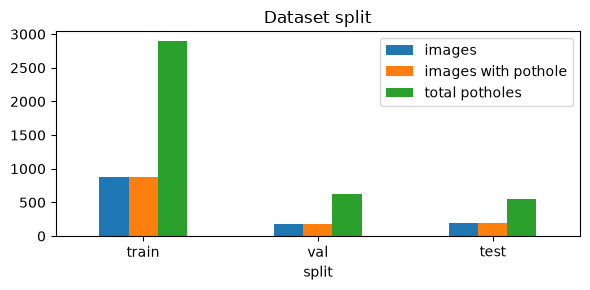

In [4]:
# 1) Split-wise counts
rows = []
for k, d in SPLIT.items():
    imgs = list_images(Path(d, 'images'))
    nb = [len(read_boxes(Path(d, 'labels', p.stem + '.txt'), 1, 1)) for p in imgs]
    rows.append({'split': k, 'images': len(imgs), 'images with pothole': int(sum(n > 0 for n in nb)),
                 'total potholes': int(sum(nb)), 'avg per image': round(float(np.mean(nb)), 2) if nb else 0})
summary = pd.DataFrame(rows); display(summary)
summary.set_index('split')[['images', 'images with pothole', 'total potholes']].plot(kind='bar', figsize=(6, 3))
plt.title('Dataset split'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

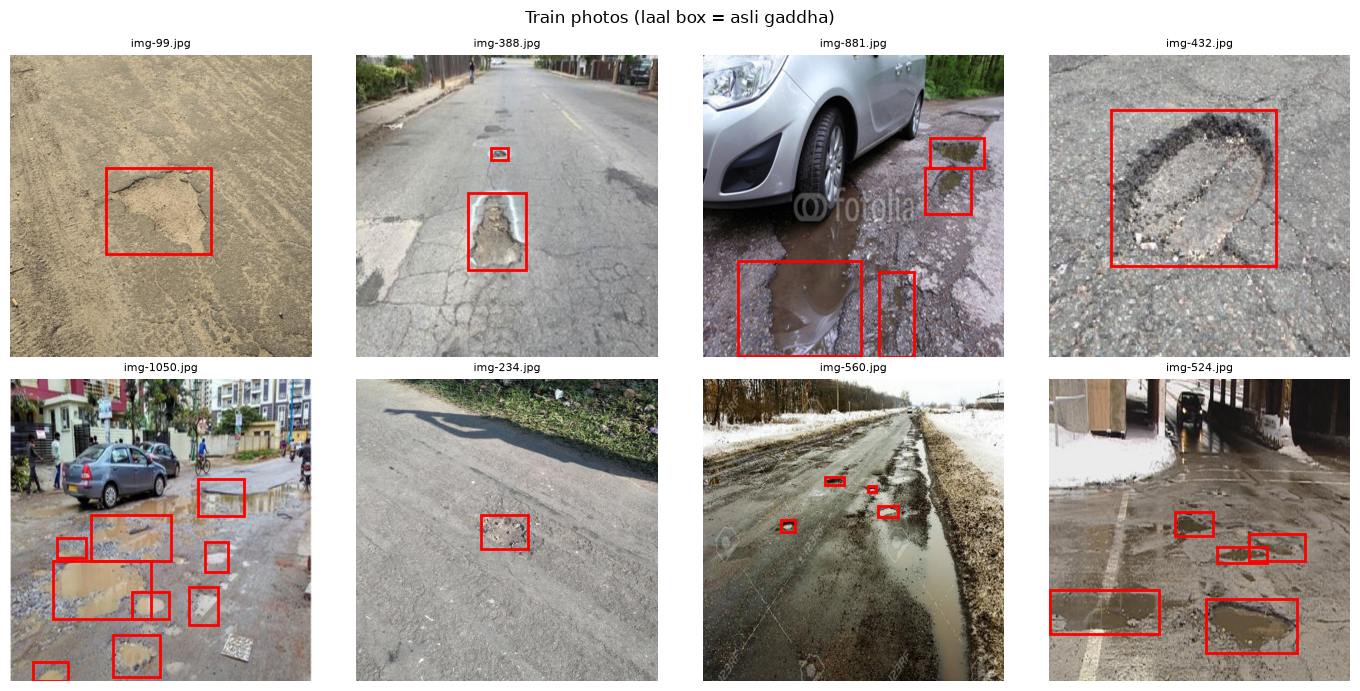

In [5]:
# 2) Sample photos + asli (ground truth) boxes
files = list_images(Path(SPLIT['train'], 'images'))
with_box = [p for p in files if read_boxes(Path(SPLIT['train'], 'labels', p.stem + '.txt'), 1, 1)]
pick = random.Random(0).sample(with_box, min(8, len(with_box))) if with_box else files[:8]
plt.figure(figsize=(14, 7))
for i, p in enumerate(pick):
    plt.subplot(2, 4, i+1); plt.imshow(read_rgb(p)); plt.axis('off')
    for x1, y1, x2, y2 in read_boxes(Path(SPLIT['train'], 'labels', p.stem + '.txt'), SIZE, SIZE):
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec='red', lw=2))
    plt.title(p.name[:22], fontsize=8)
plt.suptitle('Train photos (laal box = asli gaddha)'); plt.tight_layout(); plt.show()

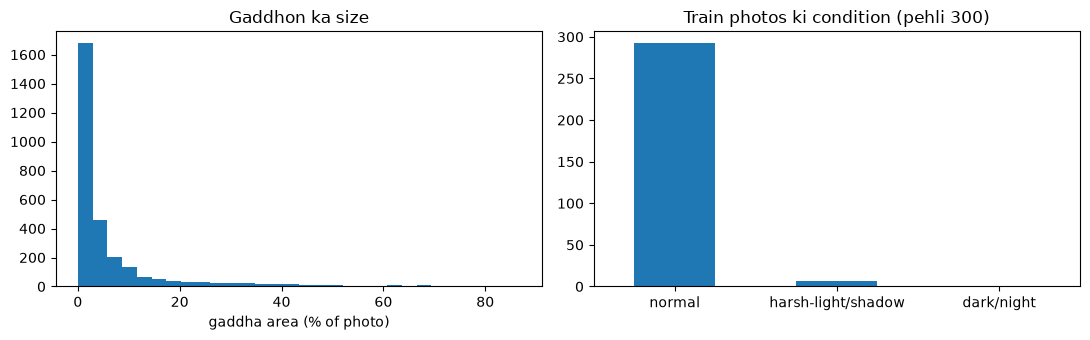

Median gaddha size: 2.07% of photo


In [6]:
# 3) Gaddhon ka size (photo ke area ka %) aur photo ki condition
areas = []
for p in files:
    for x1, y1, x2, y2 in read_boxes(Path(SPLIT['train'], 'labels', p.stem + '.txt'), SIZE, SIZE):
        areas.append(100 * (x2-x1)*(y2-y1) / (SIZE*SIZE))
def condition(path):
    g = read_rgb(path).mean(axis=2)
    if g.mean() < 0.25: return 'dark/night'
    if g.std() > 0.30:  return 'harsh-light/shadow'
    return 'normal'
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(areas, bins=30); ax[0].set_xlabel('gaddha area (% of photo)'); ax[0].set_title('Gaddhon ka size')
cond_counts = pd.Series([condition(p) for p in files[:300]]).value_counts()
cond_counts.plot(kind='bar', ax=ax[1], rot=0); ax[1].set_title('Train photos ki condition (pehli 300)')
plt.tight_layout(); plt.show()
print('Median gaddha size: %.2f%% of photo' % np.median(areas) if areas else 'Koi label nahi mila!')

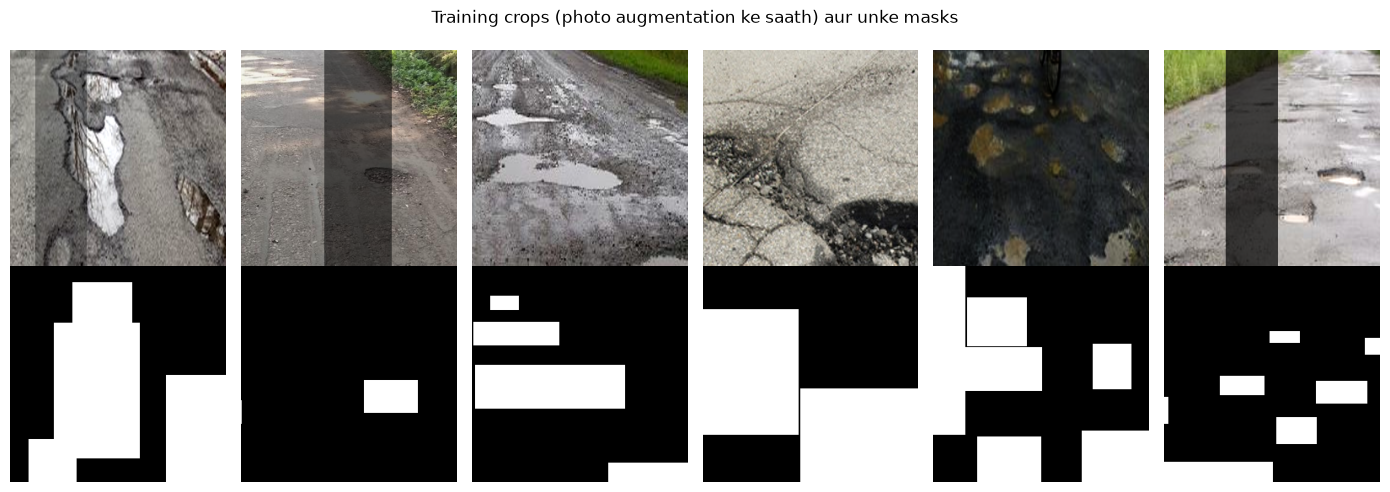

In [7]:
# 4) Model ko kya dikhega: crop (upar) aur target mask (neeche)
xb, yb = RoadTiles(SPLIT['train'], batch_size=6, train=True, photo_aug=True, steps=1)[0]
plt.figure(figsize=(14, 5))
for i in range(6):
    plt.subplot(2, 6, i+1);   plt.imshow(xb[i]); plt.axis('off')
    plt.subplot(2, 6, i+7);   plt.imshow(yb[i, ..., 0], cmap='gray'); plt.axis('off')
plt.suptitle('Training crops (photo augmentation ke saath) aur unke masks'); plt.tight_layout(); plt.show()

## Model: chhota U-Net (SAR wala, bas input 3 channel)

In [9]:
def conv_block(x, f):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    return x

def build_unet(base=16):
    inp = keras.Input((None, None, 3))
    c1 = conv_block(inp, base);   p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, base*2);  p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, base*4);  p3 = layers.MaxPooling2D()(c3)
    b  = conv_block(p3, base*8)
    u3 = conv_block(layers.Concatenate()([layers.UpSampling2D()(b),  c3]), base*4)
    u2 = conv_block(layers.Concatenate()([layers.UpSampling2D()(u3), c2]), base*2)
    u1 = conv_block(layers.Concatenate()([layers.UpSampling2D()(u2), c1]), base)
    out = layers.Conv2D(1, 1, activation='sigmoid')(u1)
    return keras.Model(inp, out, name='pothole_unet')

def bce_dice_loss(y_true, y_pred):
    y_true = ops.cast(y_true, y_pred.dtype)
    bce = ops.mean(keras.losses.binary_crossentropy(y_true, y_pred))
    inter = ops.sum(y_true * y_pred, axis=(1, 2, 3))
    denom = ops.sum(y_true, axis=(1, 2, 3)) + ops.sum(y_pred, axis=(1, 2, 3))
    dice = 1.0 - (2.0*inter + 1.0) / (denom + 1.0)
    return bce + ops.mean(dice)

def train_model(photo_aug, name, epochs=None):
    model = build_unet()
    tr = RoadTiles(SPLIT['train'], train=True,  steps=300, photo_aug=photo_aug)
    va = RoadTiles(SPLIT['val'],   train=False, steps=40)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=bce_dice_loss)
    hist = model.fit(tr, validation_data=va, epochs=2 or EPOCHS, callbacks=[
        keras.callbacks.ModelCheckpoint(str(ROOT/f'runs/{name}.keras'), monitor='val_loss', save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)])
    plt.plot(hist.history['loss'], label='train'); plt.plot(hist.history['val_loss'], label='val')
    plt.title(f'Loss: {name}'); plt.legend(); plt.show()
    return model

## Do model train  ho rhe hai 
- **Model A:** sirf flip augmentation (normal)
- **Model B:** flip + raat/contrast/shadow augmentation



Epoch 1/2
300/300 ━━━━━━━━━━━━━━━━━━━━ 279s 911ms/step - loss: 1.1477 - val_loss: 1.2978
Epoch 2/2
300/300 ━━━━━━━━━━━━━━━━━━━━ 292s 974ms/step - loss: 1.1015 - val_loss: 1.1443


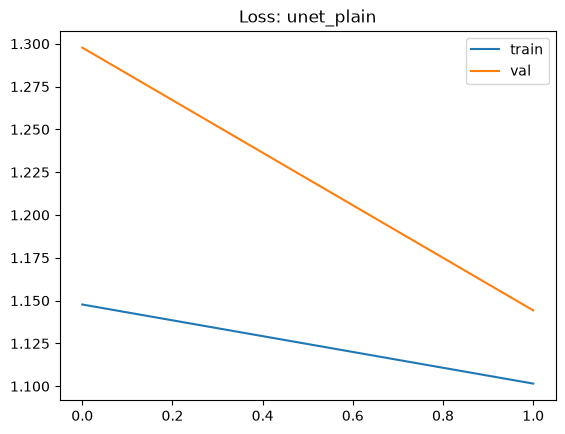

In [10]:
model_A = train_model(photo_aug=False, name='unet_plain')

Epoch 1/2
300/300 ━━━━━━━━━━━━━━━━━━━━ 251s 816ms/step - loss: 1.2306 - val_loss: 1.2388
Epoch 2/2
300/300 ━━━━━━━━━━━━━━━━━━━━ 254s 846ms/step - loss: 1.1620 - val_loss: 1.1460


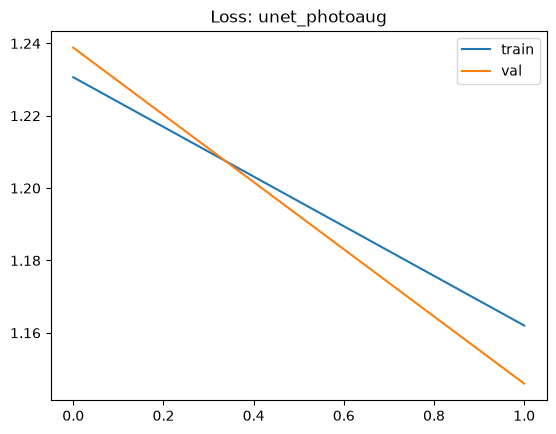

In [11]:
model_B = train_model(photo_aug=True,  name='unet_photoaug')

## Inference aur evaluation (SAR notebook wala same metric: IoU >= 0.5 par P/R/F1)

In [12]:
def predict_boxes(model, img, thr=0.5, min_area=30):
    prob = model.predict(img[None], verbose=0)[0, ..., 0]
    lab, _ = label(prob > thr)
    boxes = []
    for sl in find_objects(lab):
        h, w = sl[0].stop - sl[0].start, sl[1].stop - sl[1].start
        if h*w >= min_area:
            boxes.append([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop])
    return boxes, prob

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix*iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/union if union > 0 else 0.0

def prf(preds, gts, thr=0.5):
    tp = fp = fn = 0
    for p, g in zip(preds, gts):
        used = set()
        for pb in p:
            best, bj = 0.0, -1
            for j, gb in enumerate(g):
                if j in used: continue
                v = iou(pb, gb)
                if v > best: best, bj = v, j
            if best >= thr: tp += 1; used.add(bj)
            else: fp += 1
        fn += len(g) - len(used)
    P, R = tp/(tp+fp+1e-9), tp/(tp+fn+1e-9)
    return {'tp': tp, 'fp': fp, 'fn': fn, 'precision': P, 'recall': R, 'f1': 2*P*R/(P+R+1e-9)}

def evaluate(root, model, thr=0.5, keep=lambda p: True):
    P, G = [], []
    for im in list_images(Path(root, 'images')):
        if not keep(im):
            continue
        G.append(read_boxes(Path(root, 'labels', im.stem + '.txt'), SIZE, SIZE))
        P.append(predict_boxes(model, read_rgb(im), thr)[0])
    return prf(P, G)

def tune_threshold(val_root, model, grid=(0.3, 0.4, 0.5, 0.6, 0.7)):
    scores = {t: evaluate(val_root, model, t)['f1'] for t in grid}
    best = max(scores, key=scores.get)
    print('val F1:', {k: round(v, 3) for k, v in scores.items()}, '-> use', best)
    return best

# Threshold validation par chuno, test par nahi
THR_A = 0.5
THR_B = 0.5

print("Model A threshold:", THR_A)     ##  THR_A = tune_threshold(SPLIT['val'], model_A)
print("Model B threshold:", THR_B)      ## THR_B = tune_threshold(SPLIT['val'], model_B)

Model A threshold: 0.5
Model B threshold: 0.5


## Step B: Limitation test (raat / shadow / normal)
## Har test photo ko brightness (mean) aur contrast (std) se tag karte hain: mean < 0.25 = dark/night, std > 0.30 = harsh-light/shadow, baaki normal. Thresholds apne data ke hisaab se badal sakte ho. **Gili sadak ko automatically tag nahi kar sakte**, uske liye apni photos alag test karo.

In [13]:
TEST = SPLIT['test']
tags = {p: condition(p) for p in list_images(Path(TEST, 'images'))}
print(pd.Series(tags).value_counts())

normal                180
harsh-light/shadow      6
dark/night              1
Name: count, dtype: int64


In [14]:
rows = []
for tag in ['all', 'normal', 'dark/night', 'harsh-light/shadow']:
    keep = (lambda p: True) if tag == 'all' else (lambda p, t=tag: tags.get(p) == t)
    n_img = sum(1 for p in tags if keep(p))
    if n_img == 0:
        continue                                     # is condition ki test photo hi nahi hai
    for name, m, thr in [('A: plain aug', model_A, THR_A), ('B: photo aug', model_B, THR_B)]:
        r = evaluate(TEST, m, thr, keep=keep)
        rows.append({'subset': tag, 'photos': n_img, 'model': name, **{k: round(v, 3) for k, v in r.items()}})
result = pd.DataFrame(rows)
result

,subset,photos,model,tp,fp,fn,precision,recall,f1
0,all,187,A: plain aug,47,1133,502,0.040,0.086,0.054
1,all,187,B: photo aug,33,1110,516,0.029,0.060,0.039
2,normal,180,A: plain aug,47,1092,489,0.041,0.088,0.056
3,normal,180,B: photo aug,33,1074,503,0.030,0.062,0.040
4,dark/night,1,A: plain aug,0,1,5,0.000,0.000,0.000
5,dark/night,1,B: photo aug,0,1,5,0.000,0.000,0.000
6,harsh-light/shadow,6,A: plain aug,0,40,8,0.000,0.000,0.000
7,harsh-light/shadow,6,B: photo aug,0,35,8,0.000,0.000,0.000


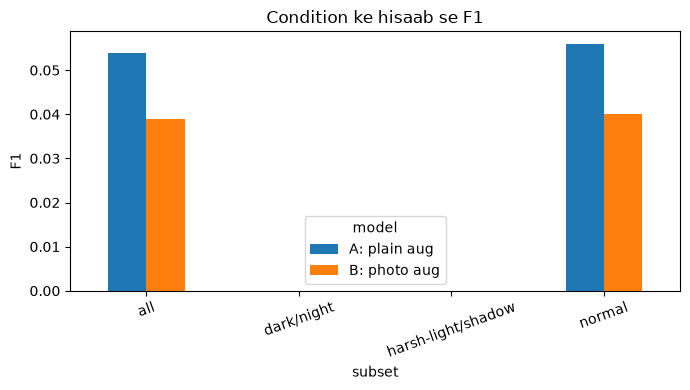

In [15]:
# Report ke liye graph: condition-wise F1
pv = result.pivot(index='subset', columns='model', values='f1')
pv.plot(kind='bar', figsize=(7, 4)); plt.ylabel('F1'); plt.title('Condition ke hisaab se F1')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## Apne shehar ki photos par fine-tune (optional par bahut zaroori)
## Public dataset ki sadak aur apne shehar ki sadak alag dikhti hain (domain shift). Apni 50-100 photos khincho, YOLO format me label karo (Roboflow ya LabelImg), aur `my_city/train|val|test/images|labels` me rakho.

In [16]:
if (ROOT/'my_city/train/images').exists():
    ft_tr = RoadTiles(ROOT/'my_city/train', train=True,  steps=60, photo_aug=True)
    ft_va = RoadTiles(ROOT/'my_city/val',   train=False, steps=15)
    model_ft = keras.models.load_model(str(ROOT/'runs/unet_photoaug.keras'), compile=False)
    model_ft.compile(optimizer=keras.optimizers.Adam(1e-4), loss=bce_dice_loss)
    model_ft.fit(ft_tr, validation_data=ft_va, epochs=2, callbacks=[
        keras.callbacks.ModelCheckpoint(str(ROOT/'runs/unet_mycity.keras'), monitor='val_loss', save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
    thr_ft = tune_threshold(ROOT/'my_city/val', model_ft)
    MC = ROOT/'my_city/test'
    print(pd.DataFrame([
        {'method': 'Public data model', **evaluate(MC, model_B, THR_B)},
        {'method': 'Fine-tuned (my city)', **evaluate(MC, model_ft, thr_ft)}]).round(3))
else:
    print('my_city folder nahi mila, ye step skip hua.')

my_city folder nahi mila, ye step skip hua.


## : Severity score aur Priority List
Score = **size (70%)** + **position (30%)** (sadak ke beech me ho to zyada khatarnak). Level: Low / Medium / High. Thresholds (0.15, 0.40) apne data par dekh kar badlo.

In [17]:
def severity(box):
    x1, y1, x2, y2 = box
    area = ((x2-x1)*(y2-y1)) / (SIZE*SIZE)
    size_s = min(1.0, area / 0.02)                          # photo ka 2% area = max size score
    cx = (x1+x2)/2 / SIZE
    center_s = 1.0 - min(1.0, abs(cx - 0.5) / 0.5)          # beech me = 1, kinare = 0
    score = 0.7*size_s + 0.3*center_s
    level = 'High' if score >= 0.40 else 'Medium' if score >= 0.15 else 'Low'
    return round(score, 2), level

def priority_list(model, thr, folder):
    rows = []
    for im in list_images(folder):
        boxes, _ = predict_boxes(model, read_rgb(im), thr)
        for b in boxes:
            s, lv = severity(b)
            rows.append({'photo': im.name, 'box': [int(v) for v in b], 'score': s, 'severity': lv})
    if not rows:
        return pd.DataFrame(columns=['photo', 'box', 'score', 'severity'])
    return pd.DataFrame(rows).sort_values('score', ascending=False).reset_index(drop=True)

plist = priority_list(model_B, THR_B, Path(SPLIT['test'], 'images'))
print(plist['severity'].value_counts().to_dict())
plist.head(15)

{'High': 540, 'Medium': 394, 'Low': 209}


,photo,box,score,severity
0,img-1011.jpg,"[0, 90, 512, 512]",1.0,High
1,img-996.jpg,"[0, 0, 512, 512]",1.0,High
2,img-1001.jpg,"[0, 0, 512, 512]",1.0,High
3,img-974.jpg,"[0, 0, 512, 512]",1.0,High
4,img-1023.jpg,"[1, 0, 512, 456]",1.0,High
5,img-143.jpg,"[186, 202, 330, 385]",1.0,High
6,img-146.jpg,"[169, 159, 336, 344]",1.0,High
7,img-818.jpg,"[0, 0, 512, 512]",1.0,High
8,img-822.jpg,"[1, 1, 512, 286]",1.0,High
9,img-860.jpg,"[1, 0, 512, 279]",1.0,High


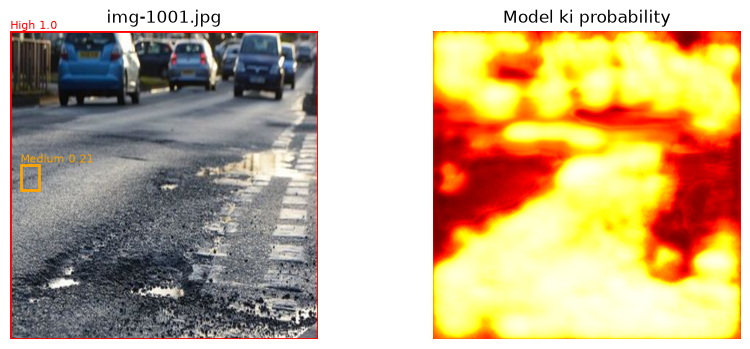

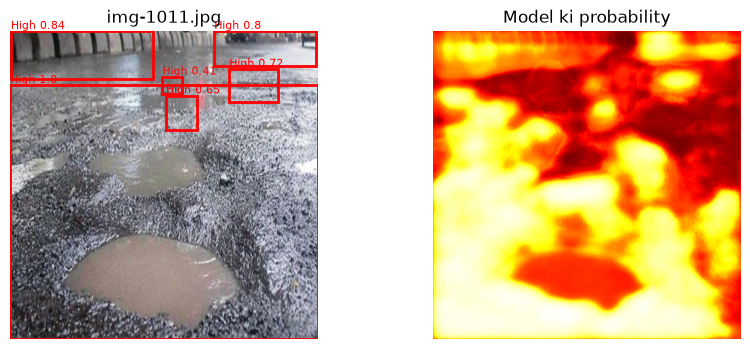

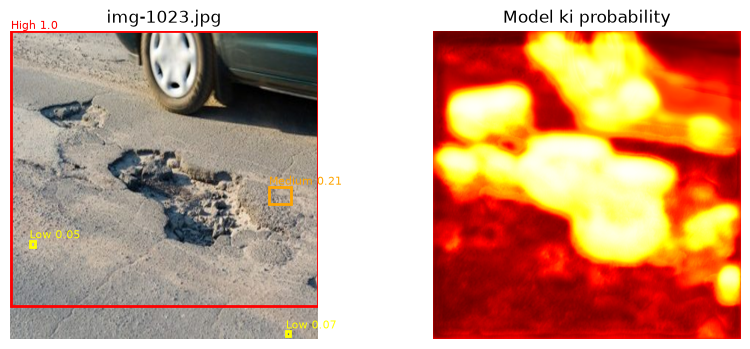

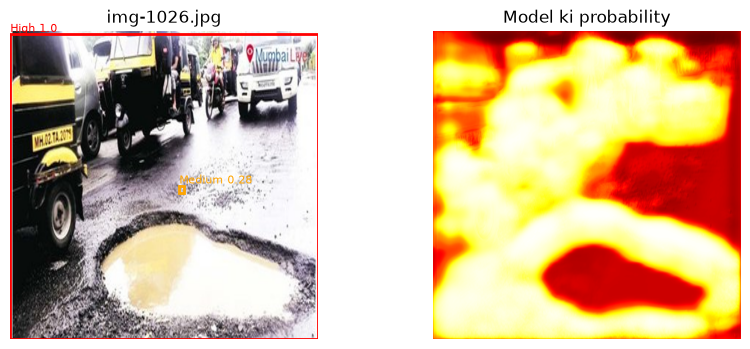

In [18]:
def show(model, thr, path):
    img = read_rgb(path)
    boxes, prob = predict_boxes(model, img, thr)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(img); plt.axis('off')
    for b in boxes:
        s, lv = severity(b)
        col = {'High': 'red', 'Medium': 'orange', 'Low': 'yellow'}[lv]
        plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=col, lw=2))
        plt.text(b[0], b[1]-4, f'{lv} {s}', color=col, fontsize=8)
    plt.title(Path(path).name[:30])
    plt.subplot(1, 2, 2); plt.imshow(prob, cmap='hot', vmin=0, vmax=1); plt.axis('off'); plt.title('Model ki probability')
    plt.show()

for p in list(tags)[:4]:
    show(model_B, THR_B, p)